# Informed RRT*

Plan a collision-free route through a continuous two-dimensional room and track how its cost improves.

RRT* selects a low-cost parent and rewires neighbours when a better path becomes available. After the first solution, Informed RRT* samples uniformly in the ellipse whose foci are the start and goal and whose major axis is the best route length. Outside that ellipse a Euclidean route cannot improve the incumbent.

In [1]:
from pathlib import Path
import sys

here = Path.cwd()
sys.path.insert(0, str(here.parent))
import numpy as np
import matplotlib.pyplot as plt

from planning import informed_rrt, segment_free
from matplotlib.patches import Circle

## Grow and rewire the tree

A line-segment distance check tests every returned edge against each circular obstacle. Descendant costs are updated after rewiring.

First solution at iteration 91 | first and last length [1.2992 1.2789] | accepted nodes 456


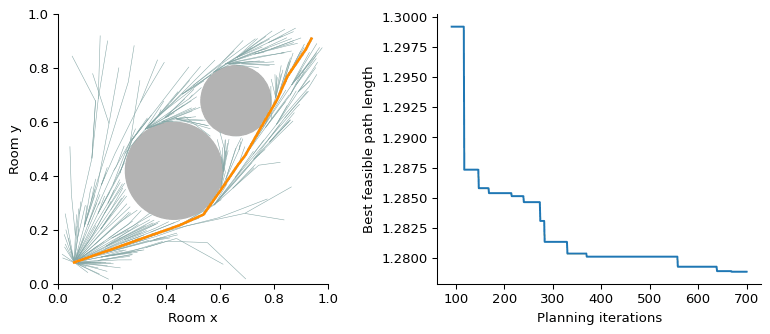

In [2]:
start = np.array([0.06, 0.08])
goal = np.array([0.94, 0.91])
obs = [(np.array([0.43, 0.42]), 0.18), (np.array([0.66, 0.68]), 0.13)]
path, cost, nodes, parents = informed_rrt(start, goal, obs, steps=700, seed=37)
assert len(path) > 1 and all(segment_free(a, b, obs) for a, b in zip(path, path[1:]))
assert np.isclose(np.linalg.norm(np.diff(path, axis=0), axis=1).sum(), cost[-1])
finite = np.flatnonzero(np.isfinite(cost))
assert np.all(np.diff(cost[finite]) <= 1.0e-8)
print(
    "First solution at iteration",
    finite[0] + 1,
    "| first and last length",
    np.round(cost[[finite[0], -1]], 4),
    "| accepted nodes",
    len(nodes),
)
fig, (a, b) = plt.subplots(1, 2, figsize=(8, 3.4), constrained_layout=True)
for centre, r in obs:
    a.add_patch(Circle(centre, r, color="0.7"))
from matplotlib.collections import LineCollection

a.add_collection(
    LineCollection(
        [[nodes[j], nodes[i]] for i, j in enumerate(parents) if j >= 0],
        colors="#84a6a5",
        linewidths=0.4,
    )
)
a.plot(*path.T, color="darkorange", lw=2)
a.set(aspect="equal", xlim=(0, 1), ylim=(0, 1), xlabel="Room x", ylabel="Room y")
b.plot(finite + 1, cost[finite])
b.set(xlabel="Planning iterations", ylabel="Best feasible path length")
plt.show()

## Interpreting the result

The curve is a best-so-far cost for one seeded run. Collision-free edges and monotonically improving cost can be checked directly. A finite run gives no certificate of global optimality.

## Exercise

Compare several seeds and report the distribution of time to first solution.

## References

[Gammell, Srinivasa and Barfoot, Informed RRT*](https://arxiv.org/abs/1404.2334)

[Karaman and Frazzoli, Sampling-based Algorithms for Optimal Motion Planning](https://arxiv.org/abs/1105.1186)